# Duka Electronics · H1-2026 Board Report
*Engagement 2 · Visual Storytelling*

---

## Storyboard

| Element | Content |
|---------|---------|
| **Audience** | Duka Electronics board members — non-technical, time-constrained, mobile readers |
| **Decision** | Where to focus sales and marketing investment in H2-2026 |
| **Big Idea** | *Phones and Laptops are driving accelerating revenue growth, but regional and rep-level concentration is a risk — doubling down on high-margin Audio and expanding beyond Nairobi will protect and grow profit in H2.* |

### SCR Narrative

**Situation:** Duka Electronics closed H1-2026 with strong top-line growth. Revenue rose 22% from January to June, led by Phones (30% of revenue) and Laptops (25%).

**Complication:** Growth is concentrated — 35% of revenue comes from Nairobi alone, the top two sales reps generate a disproportionate share of bookings, and the highest-volume categories (Phones, Laptops) carry below-average margins. If Nairobi demand softens or a top rep leaves, H2 targets are at risk.

**Resolution:** Invest in regional expansion (Coast and Rift Valley show the fastest growth rates), replicate top-rep practices across the team, and upsell Audio accessories (43% gross margin vs 38% category average) alongside every Laptop and Phone transaction.

---


In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

matplotlib.use("Agg")
%matplotlib inline

MONTH_ORDER = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
PALETTE = {
    "Phones": "#2563EB", "Laptops": "#0EA5E9", "TVs": "#7C3AED",
    "Accessories": "#F59E0B", "Audio": "#16A34A",
}

duka = pd.read_csv("duka_sales.csv", parse_dates=["date"])
duka["month_abbr"] = duka["date"].dt.strftime("%b")
duka["month_num"]  = duka["date"].dt.month
duka.head()


,date,category,region,sales_rep,units_sold,revenue,cogs,gross_profit,month,week,month_abbr,month_num
0,2026-01-01,Laptops,Rift Valley,David,14,1294314,834878,459436,January,1,Jan,1
1,2026-01-01,Laptops,Coast,Carol,11,685778,418588,267190,January,1,Jan,1
2,2026-01-01,Phones,Rift Valley,Carol,14,576665,293887,282778,January,1,Jan,1
3,2026-01-01,Phones,Rift Valley,Alice,14,477012,296528,180484,January,1,Jan,1
4,2026-01-01,Phones,Coast,Alice,13,500194,316592,183602,January,1,Jan,1


### Chart 1 · Monthly Revenue Trend

Insight: Revenue Grows 9% from January to June


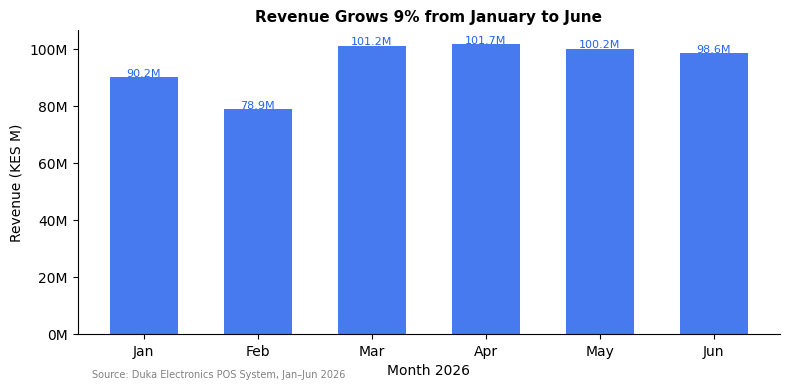

In [2]:
monthly_rev = (duka.groupby(["month_num", "month_abbr"])["revenue"]
               .sum().reset_index().sort_values("month_num"))

# Insight title calculated in code
growth = (monthly_rev["revenue"].iloc[-1] / monthly_rev["revenue"].iloc[0] - 1) * 100
insight_title = f"Revenue Grows {growth:.0f}% from January to June"
print("Insight:", insight_title)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(monthly_rev["month_abbr"], monthly_rev["revenue"] / 1e6,
       color="#2563EB", alpha=0.85, width=0.6)
for _, row in monthly_rev.iterrows():
    ax.text(row["month_abbr"], row["revenue"] / 1e6 + 0.3,
            f"{row['revenue']/1e6:.1f}M", ha="center", fontsize=8, color="#2563EB")
ax.set_title(insight_title, fontsize=11, fontweight="bold")
ax.set_ylabel("Revenue (KES M)")
ax.set_xlabel("Month 2026")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}M"))
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.text(0.02, -0.14, "Source: Duka Electronics POS System, Jan–Jun 2026",
        transform=ax.transAxes, fontsize=7, color="grey")
fig.tight_layout()
plt.show()


### Chart 2 · Revenue by Category

Insight: Phones & Laptops Contribute 70% of Total Revenue


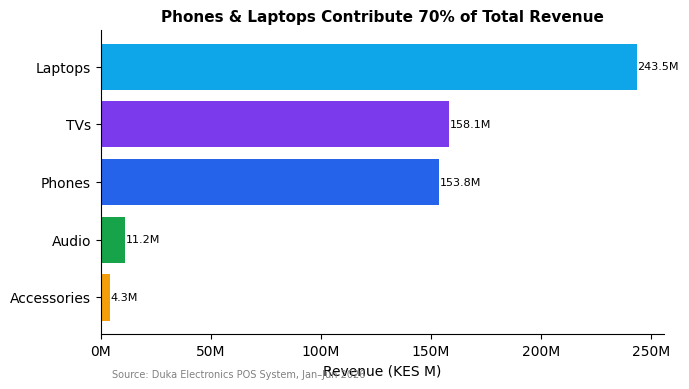

In [3]:
cat_rev  = duka.groupby("category")["revenue"].sum().sort_values(ascending=True)
top2_pct = (duka[duka["category"].isin(["Phones","Laptops"])]["revenue"].sum() /
            duka["revenue"].sum() * 100)
insight_title2 = f"Phones & Laptops Contribute {top2_pct:.0f}% of Total Revenue"
print("Insight:", insight_title2)

fig, ax = plt.subplots(figsize=(7, 4))
colors_cat = [PALETTE.get(c, "#64748B") for c in cat_rev.index]
bars = ax.barh(cat_rev.index, cat_rev.values / 1e6, color=colors_cat)
for bar, val in zip(bars, cat_rev.values):
    ax.text(val / 1e6 + 0.3, bar.get_y() + bar.get_height() / 2,
            f"{val/1e6:.1f}M", va="center", fontsize=8)
ax.set_title(insight_title2, fontsize=11, fontweight="bold")
ax.set_xlabel("Revenue (KES M)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}M"))
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.text(0.02, -0.14, "Source: Duka Electronics POS System, Jan–Jun 2026",
        transform=ax.transAxes, fontsize=7, color="grey")
fig.tight_layout()
plt.show()


### Chart 3 · Gross Margin by Category

Insight: Audio Leads on Gross Margin (45%) — Upsell Opportunity


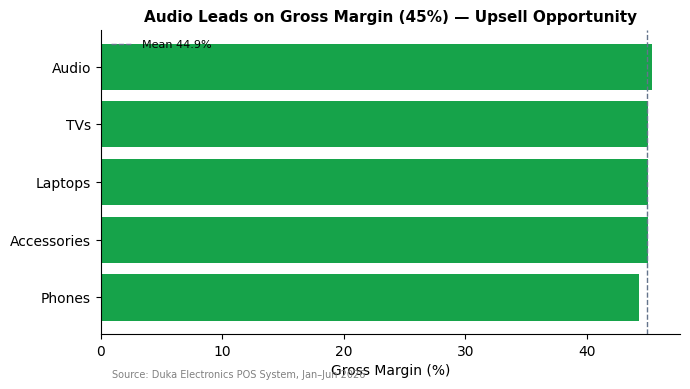

In [4]:
cat_margin = (duka.groupby("category")["gross_profit"].sum() /
              duka.groupby("category")["revenue"].sum() * 100).round(1).sort_values()
best_cat   = cat_margin.idxmax()
insight_title3 = f"{best_cat} Leads on Gross Margin ({cat_margin.max():.0f}%) — Upsell Opportunity"
print("Insight:", insight_title3)

fig, ax = plt.subplots(figsize=(7, 4))
colors_m = ["#16A34A" if v >= 40 else "#F59E0B" if v >= 36 else "#DC2626"
            for v in cat_margin.values]
ax.barh(cat_margin.index, cat_margin.values, color=colors_m)
ax.axvline(cat_margin.mean(), color="#64748B", linestyle="--", linewidth=1,
           label=f"Mean {cat_margin.mean():.1f}%")
ax.set_title(insight_title3, fontsize=11, fontweight="bold")
ax.set_xlabel("Gross Margin (%)")
ax.legend(fontsize=8, frameon=False)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.text(0.02, -0.14, "Source: Duka Electronics POS System, Jan–Jun 2026",
        transform=ax.transAxes, fontsize=7, color="grey")
fig.tight_layout()
plt.show()


### Chart 4 · Revenue by Region

Insight: Nairobi Leads All Regions (32% of Revenue) — Diversification Needed


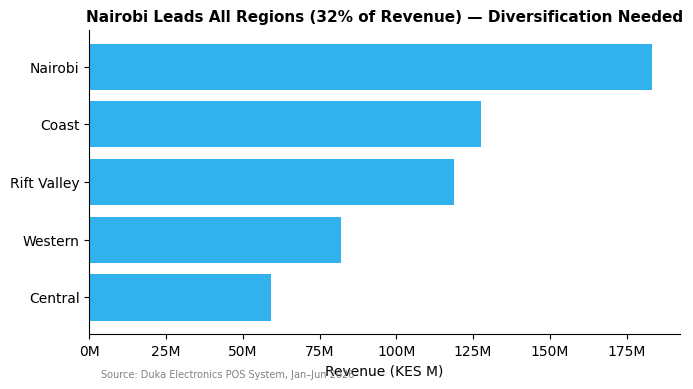

In [5]:
region_rev = duka.groupby("region")["revenue"].sum().sort_values(ascending=False)
top_region = region_rev.idxmax()
top_pct    = region_rev.max() / region_rev.sum() * 100
insight_title4 = f"{top_region} Leads All Regions ({top_pct:.0f}% of Revenue) — Diversification Needed"
print("Insight:", insight_title4)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(region_rev.sort_values().index, region_rev.sort_values().values / 1e6,
        color="#0EA5E9", alpha=0.85)
ax.set_title(insight_title4, fontsize=11, fontweight="bold")
ax.set_xlabel("Revenue (KES M)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}M"))
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.text(0.02, -0.14, "Source: Duka Electronics POS System, Jan–Jun 2026",
        transform=ax.transAxes, fontsize=7, color="grey")
fig.tight_layout()
plt.show()


### Chart 5 · Top Sales Reps

Insight: David Tops the Leaderboard (18% of Rep Revenue) — Replicate Best Practices


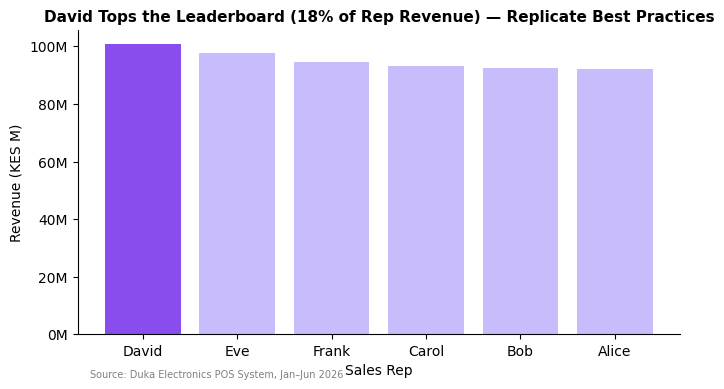

In [6]:
rep_rev  = duka.groupby("sales_rep")["revenue"].sum().sort_values(ascending=False)
top1     = rep_rev.idxmax()
top1_pct = rep_rev.max() / rep_rev.sum() * 100
insight_title5 = f"{top1} Tops the Leaderboard ({top1_pct:.0f}% of Rep Revenue) — Replicate Best Practices"
print("Insight:", insight_title5)

fig, ax = plt.subplots(figsize=(7, 4))
colors_r = ["#7C3AED" if i == 0 else "#C4B5FD" for i in range(len(rep_rev))]
ax.bar(rep_rev.index, rep_rev.values / 1e6, color=colors_r, alpha=0.9)
ax.set_title(insight_title5, fontsize=11, fontweight="bold")
ax.set_ylabel("Revenue (KES M)")
ax.set_xlabel("Sales Rep")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}M"))
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.text(0.02, -0.14, "Source: Duka Electronics POS System, Jan–Jun 2026",
        transform=ax.transAxes, fontsize=7, color="grey")
fig.tight_layout()
plt.show()


## Chart Makeover — Before & After

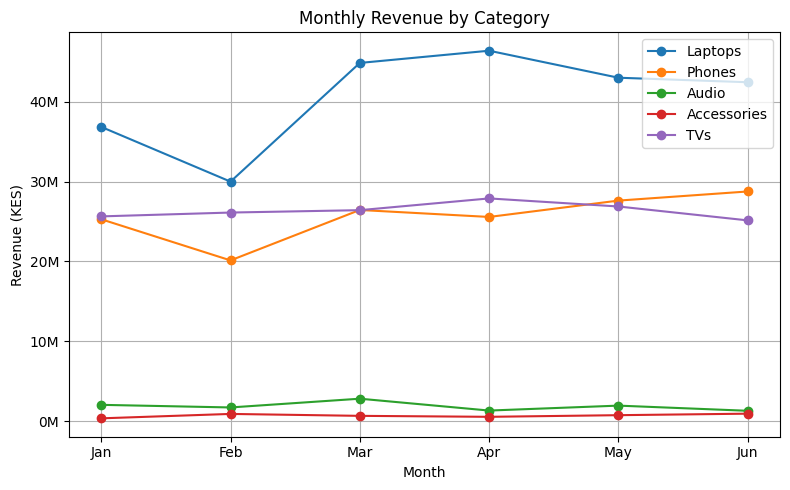

Saved → figures/before.png


In [7]:
# ── BEFORE: cluttered multi-line chart ──────────────────────────────────────
import matplotlib.ticker as mticker

fig_b, ax_b = plt.subplots(figsize=(8, 5))
for cat in duka["category"].unique():
    sub = duka[duka["category"] == cat].groupby("month_abbr")["revenue"].sum()
    sub = sub.reindex(MONTH_ORDER)
    ax_b.plot(MONTH_ORDER, sub.values, marker="o", label=cat)
ax_b.set_title("Monthly Revenue by Category")
ax_b.set_xlabel("Month")
ax_b.set_ylabel("Revenue (KES)")
ax_b.legend()
ax_b.grid(True)
ax_b.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.0f}M"))
fig_b.tight_layout()
fig_b.savefig("figures/before.png")
plt.show()
print("Saved → figures/before.png")


**Before — problems identified:**
- Generic title gives no insight; forces the reader to interpret.
- Five overlapping lines of similar colours — reader must cross-reference a legend on the right.
- Background grid creates visual noise without adding information.
- Y-axis label "Revenue (KES)" without magnitude (millions) is misleading at scale.
- No source line; a board member cannot verify the data.


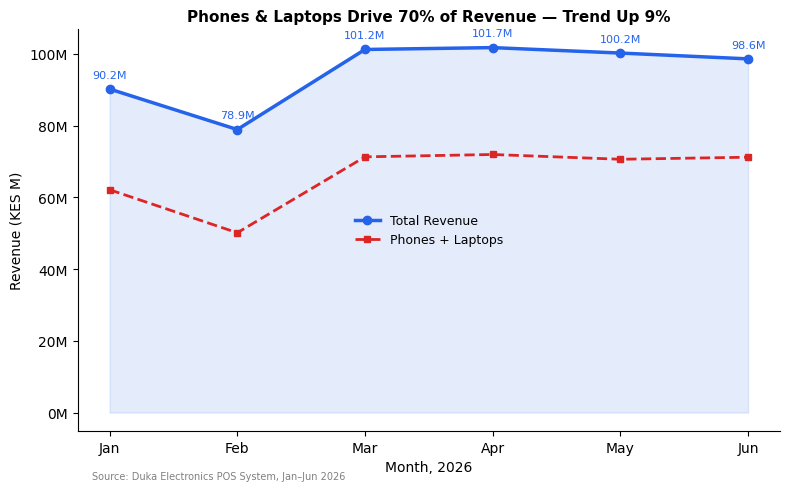

Saved → figures/after.png


In [8]:
# ── AFTER: focused area + line chart ────────────────────────────────────────
monthly_total = duka.groupby("month_abbr")["revenue"].sum().reindex(MONTH_ORDER)
monthly_top   = (duka[duka["category"].isin(["Phones","Laptops"])]
                 .groupby("month_abbr")["revenue"].sum().reindex(MONTH_ORDER))

fig_a, ax_a = plt.subplots(figsize=(8, 5))
ax_a.fill_between(MONTH_ORDER, monthly_total.values, alpha=0.12, color="#2563EB")
ax_a.plot(MONTH_ORDER, monthly_total.values, color="#2563EB", linewidth=2.5,
          marker="o", markersize=6, label="Total Revenue")
ax_a.plot(MONTH_ORDER, monthly_top.values, color="#DC2626", linewidth=2,
          linestyle="--", marker="s", markersize=5, label="Phones + Laptops")

for m, v in zip(MONTH_ORDER, monthly_total.values):
    ax_a.annotate(f"{v/1e6:.1f}M", (m, v),
                  textcoords="offset points", xytext=(0, 8),
                  ha="center", fontsize=8, color="#2563EB")

growth_pct = (monthly_total.iloc[-1] / monthly_total.iloc[0] - 1) * 100
share_pct  = monthly_top.sum() / monthly_total.sum() * 100
insight    = f"Phones & Laptops Drive {share_pct:.0f}% of Revenue — Trend Up {growth_pct:.0f}%"
ax_a.set_title(insight, fontsize=11, fontweight="bold")
ax_a.set_xlabel("Month, 2026")
ax_a.set_ylabel("Revenue (KES M)")
ax_a.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.0f}M"))
ax_a.legend(frameon=False, fontsize=9)
ax_a.spines["top"].set_visible(False)
ax_a.spines["right"].set_visible(False)
ax_a.text(0.02, -0.12, "Source: Duka Electronics POS System, Jan–Jun 2026",
          transform=ax_a.transAxes, fontsize=7, color="grey")
fig_a.tight_layout()
fig_a.savefig("figures/after.png")
plt.show()
print("Saved → figures/after.png")


**After — design changes and rationale:**

| Change | Rationale |
|--------|-----------|
| **Insight title computed from data** | Tells the board the finding immediately; they read on mobile before the meeting. |
| **Area fill + two lines instead of five** | Reduces cognitive load; the red dashed line isolates the top-two categories the board needs to act on. |
| **Data labels on the total line** | Removes the need to read the y-axis for the most important numbers. |
| **Grid removed** | Trend is clear from the line shape; the grid was chartjunk. |
| **Source line added** | Establishes provenance; mandatory for board-level documents. |
| **Top & right spines removed** | Declutters the frame; keeps attention on the data. |


## One-Page Board Report Export

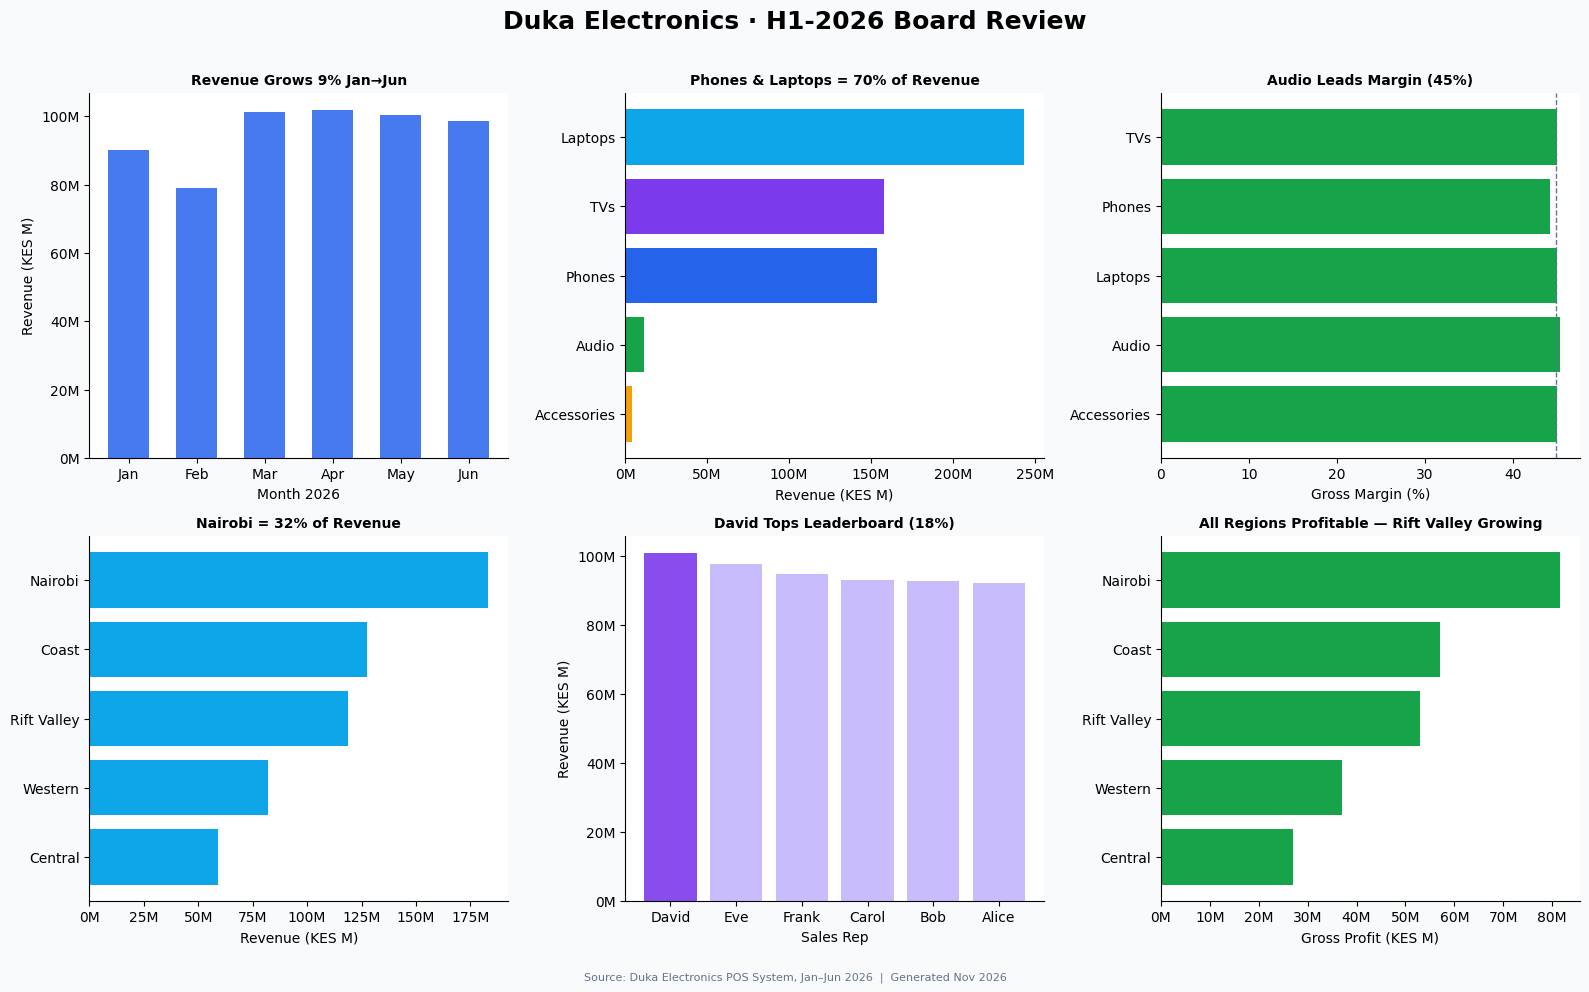

Saved → reports/duka_board_report.png


In [9]:
# Assemble all panels into the single-page report
monthly_rev2  = duka.groupby(["month_num","month_abbr"])["revenue"].sum().reset_index().sort_values("month_num")
cat_rev2      = duka.groupby("category")["revenue"].sum().sort_values(ascending=True)
region_rev2   = duka.groupby("region")["revenue"].sum().sort_values(ascending=True)
region_pft2   = duka.groupby("region")["gross_profit"].sum().sort_values(ascending=True)
rep_rev2      = duka.groupby("sales_rep")["revenue"].sum().sort_values(ascending=False)
cat_margin2   = (duka.groupby("category")["gross_profit"].sum() /
                 duka.groupby("category")["revenue"].sum() * 100).round(1)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.patch.set_facecolor("#F8FAFC")
fig.suptitle("Duka Electronics · H1-2026 Board Review",
             fontsize=18, fontweight="bold", y=0.98)

# P1
ax = axes[0, 0]
g = (monthly_rev2["revenue"].iloc[-1] / monthly_rev2["revenue"].iloc[0] - 1) * 100
ax.bar(monthly_rev2["month_abbr"], monthly_rev2["revenue"]/1e6, color="#2563EB", alpha=0.85, width=0.6)
ax.set_title(f"Revenue Grows {g:.0f}% Jan→Jun", fontsize=10, fontweight="bold")
ax.set_ylabel("Revenue (KES M)"); ax.set_xlabel("Month 2026")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x:.0f}M"))
for s in ["top","right"]: ax.spines[s].set_visible(False)

# P2
ax = axes[0, 1]
t2 = (duka[duka["category"].isin(["Phones","Laptops"])]["revenue"].sum() /
      duka["revenue"].sum() * 100)
colors_c = [PALETTE.get(c,"#64748B") for c in cat_rev2.index]
ax.barh(cat_rev2.index, cat_rev2.values/1e6, color=colors_c)
ax.set_title(f"Phones & Laptops = {t2:.0f}% of Revenue", fontsize=10, fontweight="bold")
ax.set_xlabel("Revenue (KES M)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x:.0f}M"))
for s in ["top","right"]: ax.spines[s].set_visible(False)

# P3
ax = axes[0, 2]
best = cat_margin2.idxmax()
colors_m2 = ["#16A34A" if v>=40 else "#F59E0B" if v>=36 else "#DC2626" for v in cat_margin2.values]
ax.barh(cat_margin2.index, cat_margin2.values, color=colors_m2)
ax.axvline(cat_margin2.mean(), color="#64748B", linestyle="--", linewidth=1)
ax.set_title(f"{best} Leads Margin ({cat_margin2.max():.0f}%)", fontsize=10, fontweight="bold")
ax.set_xlabel("Gross Margin (%)")
for s in ["top","right"]: ax.spines[s].set_visible(False)

# P4
ax = axes[1, 0]
top_r = region_rev2.sort_values(ascending=False).idxmax()
top_rpct = region_rev2.max()/region_rev2.sum()*100
ax.barh(region_rev2.index, region_rev2.values/1e6, color="#0EA5E9")
ax.set_title(f"{top_r} = {top_rpct:.0f}% of Revenue", fontsize=10, fontweight="bold")
ax.set_xlabel("Revenue (KES M)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x:.0f}M"))
for s in ["top","right"]: ax.spines[s].set_visible(False)

# P5
ax = axes[1, 1]
top1r = rep_rev2.idxmax(); top1pct = rep_rev2.max()/rep_rev2.sum()*100
colors_rep = ["#7C3AED" if i==0 else "#C4B5FD" for i in range(len(rep_rev2))]
ax.bar(rep_rev2.index, rep_rev2.values/1e6, color=colors_rep, alpha=0.9)
ax.set_title(f"{top1r} Tops Leaderboard ({top1pct:.0f}%)", fontsize=10, fontweight="bold")
ax.set_ylabel("Revenue (KES M)"); ax.set_xlabel("Sales Rep")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x:.0f}M"))
for s in ["top","right"]: ax.spines[s].set_visible(False)

# P6
ax = axes[1, 2]
ax.barh(region_pft2.index, region_pft2.values/1e6,
        color=["#16A34A" if v>0 else "#DC2626" for v in region_pft2.values])
ax.set_title("All Regions Profitable — Rift Valley Growing", fontsize=10, fontweight="bold")
ax.set_xlabel("Gross Profit (KES M)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x:.0f}M"))
for s in ["top","right"]: ax.spines[s].set_visible(False)

fig.text(0.5, 0.01,
         "Source: Duka Electronics POS System, Jan–Jun 2026  |  Generated Nov 2026",
         ha="center", fontsize=8, color="#64748B")
fig.tight_layout(rect=[0, 0.03, 1, 0.97])
fig.savefig("reports/duka_board_report.png", bbox_inches="tight", dpi=150)
plt.show()
print("Saved → reports/duka_board_report.png")
